In [1]:
# CELL 1 — imports, project discovery, and paths
from pathlib import Path
import ast
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("default")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

DATASET_NAME = (
    "qol_stress-a-multimodal-dataset-of-physiological-and-self-reported-stress-responses-1.0.0"
)
PROJECT_ROOT_OVERRIDE = None  # Optionally set to Path(r"D:\\...\\ml-workstream-2")


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Cannot locate ml-workstream-2 from {start}. Expected a parent with data/raw and notebooks."
    )


PROJECT_ROOT = (
    Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    if PROJECT_ROOT_OVERRIDE is not None
    else find_project_root(Path.cwd())
)
DATASET_ROOT = PROJECT_ROOT / "data" / "raw" / DATASET_NAME
DATA_DIR = DATASET_ROOT / "data"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
TABLES_DIR = REPORTS_DIR / "tables"

for folder in (REPORTS_DIR, FIGURES_DIR, TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset data folder not found: {DATA_DIR}")

print("Project root :", PROJECT_ROOT)
print("Data folder  :", DATA_DIR)
print("Reports      :", REPORTS_DIR)
print("Figures      :", FIGURES_DIR)
print("Tables       :", TABLES_DIR)

Project root : D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2
Data folder  : D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\data\raw\qol_stress-a-multimodal-dataset-of-physiological-and-self-reported-stress-responses-1.0.0\data
Reports      : D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports
Figures      : D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\figures
Tables       : D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\tables


In [2]:
# CELL 2 — load dataset collections
EXPECTED_COLLECTIONS = [
    "ecg", "eda", "fitbit_heart_rate_per_minute",
    "fitbit_heart_rate_per_second", "fitbit_heart_rate_summary",
    "participants", "pss_14", "stai",
]


def normalised_stem(path: Path) -> str:
    return path.stem.lower() if path.suffix else path.name.lower()


def read_collection(path: Path) -> pd.DataFrame:
    return pd.read_csv(
        path,
        dtype={"username": "string", "participant_id": "string", "subject_id": "string"},
        low_memory=False,
        encoding="utf-8-sig",
    )


files_by_stem = {}
for path in DATA_DIR.iterdir():
    if path.is_file():
        files_by_stem.setdefault(normalised_stem(path), []).append(path)

data = {}
source_paths = {}
missing_collections = []
for name in EXPECTED_COLLECTIONS:
    matches = files_by_stem.get(name, [])
    if not matches:
        missing_collections.append(name)
        continue
    if len(matches) > 1:
        raise RuntimeError(f"Multiple files found for {name}: {[p.name for p in matches]}")
    source_paths[name] = matches[0]
    data[name] = read_collection(matches[0])

if not data:
    raise RuntimeError(f"No recognised dataset CSVs found in {DATA_DIR}")

print("Loaded collections:", list(data))
print("Missing expected collections:", missing_collections or "None")

load_summary = []
for name, df in data.items():
    id_col = next((c for c in ("username", "participant_id", "subject_id") if c in df.columns), None)
    load_summary.append({
        "collection": name,
        "file": source_paths[name].name,
        "rows": len(df),
        "columns": len(df.columns),
        "participant_count": int(df[id_col].nunique(dropna=True)) if id_col else np.nan,
        "duplicate_rows": int(df.duplicated().sum()),
    })
load_summary = pd.DataFrame(load_summary)
display(load_summary)
load_summary.to_csv(TABLES_DIR / "eda_collection_load_summary.csv", index=False)

Loaded collections: ['ecg', 'eda', 'fitbit_heart_rate_per_minute', 'fitbit_heart_rate_per_second', 'fitbit_heart_rate_summary', 'participants', 'pss_14', 'stai']
Missing expected collections: None


,collection,file,rows,columns,participant_count,duplicate_rows
0,ecg,ecg.csv,132,13,66,0
1,eda,eda.csv,20094,6,64,1542
2,fitbit_heart_rate_per_minute,fitbit_heart_rate_per_minute.csv,2131,3,66,0
3,fitbit_heart_rate_per_second,fitbit_heart_rate_per_second.csv,54462,3,66,0
4,fitbit_heart_rate_summary,fitbit_heart_rate_summary.csv,264,6,66,0
5,participants,participants.csv,66,5,66,0
6,pss_14,pss_14.csv,66,17,66,0
7,stai,stai.csv,132,24,66,0


In [3]:
# CELL 3 — schema and missingness table
schema_rows = []
for name, df in data.items():
    for col in df.columns:
        s = df[col]
        schema_rows.append({
            "collection": name,
            "column": col,
            "dtype": str(s.dtype),
            "non_null": int(s.notna().sum()),
            "missing": int(s.isna().sum()),
            "missing_pct": round(float(s.isna().mean() * 100), 2),
            "unique_non_null": int(s.nunique(dropna=True)),
            "example_values": " | ".join(s.dropna().astype(str).head(3).tolist()),
        })
schema = pd.DataFrame(schema_rows)
display(schema)
schema.to_csv(TABLES_DIR / "eda_schema_missingness.csv", index=False)

# Participant ID counts by collection (IDs are used only for linkage/coverage).
coverage_rows = []
for name, df in data.items():
    id_col = next((c for c in ("username", "participant_id", "subject_id") if c in df.columns), None)
    coverage_rows.append({
        "collection": name,
        "id_column": id_col or "not found",
        "unique_participants": int(df[id_col].nunique(dropna=True)) if id_col else np.nan,
        "rows_without_id": int(df[id_col].isna().sum()) if id_col else np.nan,
    })
participant_coverage = pd.DataFrame(coverage_rows)
display(participant_coverage)
participant_coverage.to_csv(TABLES_DIR / "eda_participant_coverage.csv", index=False)

,collection,column,dtype,non_null,missing,missing_pct,unique_non_null,example_values
0,ecg,_id,str,132,0,0.0,132,685a7de0963f0d4b7ea5dd3c | 685a7e17963f0d4b7ea5dd41 | 685a7e49963f0d4b7ea5dd42
1,ecg,reading_id,str,132,0,0.0,130,b88b3b90-b60c-11ef-8080-808080808080 | 85d45fe0-b60e-11ef-8080-808080808080 | a7992380-4147-11f0...
2,ecg,reading_time,str,132,0,0.0,132,10:05:22 | 10:18:16 | 15:27:25
3,ecg,wire_id,str,132,0,0.0,2,0199283d6f42 | 0199283d6f42 | 817821915242
4,ecg,result_classification,str,132,0,0.0,2,UNCLASSIFIABLE | UNCLASSIFIABLE | NSR
...,...,...,...,...,...,...,...,...
72,stai,"""I feel strained""",str,132,0,0.0,4,0. Not at all | 2. Quite a bit | 0. Not at all
73,stai,I feel nervous,str,132,0,0.0,4,0. Not at all | 0. Not at all | 0. Not at all
74,stai,I feel satisfied,str,132,0,0.0,4,3. Very much | 2. Quite a bit | 1. A little
75,stai,I feel secure,str,132,0,0.0,3,3. Very much | 2. Quite a bit | 2. Quite a bit


,collection,id_column,unique_participants,rows_without_id
0,ecg,username,66,0
1,eda,username,64,0
2,fitbit_heart_rate_per_minute,username,66,0
3,fitbit_heart_rate_per_second,username,66,0
4,fitbit_heart_rate_summary,username,66,0
5,participants,username,66,0
6,pss_14,username,66,0
7,stai,username,66,0


,collection,phase,rows
0,ecg,RELAX,66
1,ecg,STRESS,66
2,eda,RELAX,10367
3,eda,STRESS,9727
4,stai,RELAX,66
5,stai,STRESS,66


,collection,phase,participants,rows
0,ecg,RELAX,66,66
1,ecg,STRESS,66,66
2,eda,RELAX,64,10367
3,eda,STRESS,60,9727
4,stai,RELAX,66,66
5,stai,STRESS,66,66


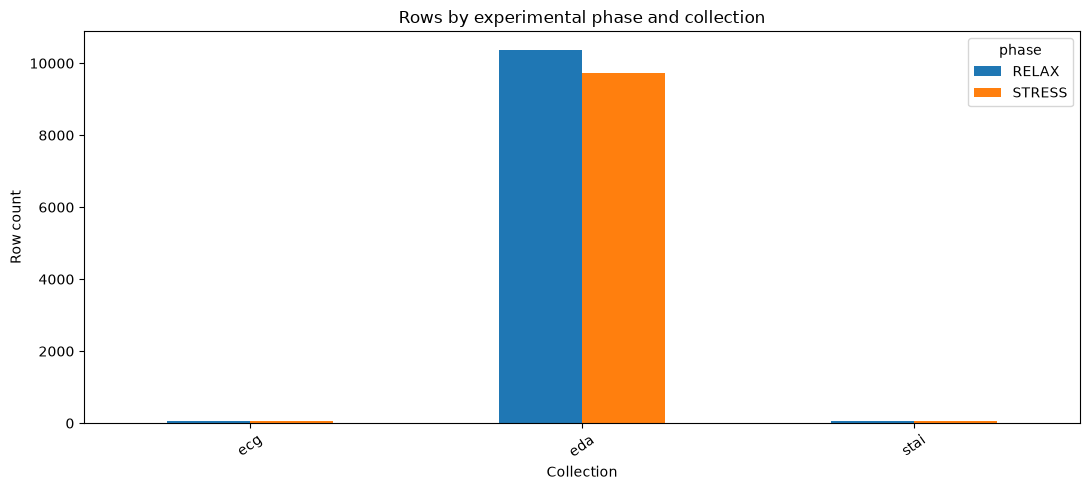

In [4]:
# CELL 4 — phase label distributions and per-participant coverage
phase_rows = []
phase_coverage_rows = []
for name, df in data.items():
    phase_col = next((c for c in df.columns if c.lower() == "phase"), None)
    id_col = next((c for c in ("username", "participant_id", "subject_id") if c in df.columns), None)
    if phase_col is None:
        continue
    phase = df[phase_col].astype("string").str.strip().str.upper()
    counts = phase.value_counts(dropna=False)
    for label, count in counts.items():
        phase_rows.append({
            "collection": name,
            "phase": "<MISSING>" if pd.isna(label) else str(label),
            "rows": int(count),
        })
    if id_col:
        temp = pd.DataFrame({"participant": df[id_col], "phase": phase})
        temp = temp.dropna(subset=["participant"])
        for label, group in temp.groupby("phase", dropna=False):
            phase_coverage_rows.append({
                "collection": name,
                "phase": "<MISSING>" if pd.isna(label) else str(label),
                "participants": int(group["participant"].nunique()),
                "rows": int(len(group)),
            })

phase_distribution = pd.DataFrame(phase_rows)
phase_coverage = pd.DataFrame(phase_coverage_rows)
display(phase_distribution)
display(phase_coverage)
phase_distribution.to_csv(TABLES_DIR / "eda_phase_distribution.csv", index=False)
phase_coverage.to_csv(TABLES_DIR / "eda_phase_participant_coverage.csv", index=False)

if not phase_distribution.empty:
    pivot = phase_distribution.pivot(index="collection", columns="phase", values="rows").fillna(0)
    ax = pivot.plot(kind="bar", figsize=(11, 5))
    ax.set_title("Rows by experimental phase and collection")
    ax.set_xlabel("Collection")
    ax.set_ylabel("Row count")
    ax.tick_params(axis="x", rotation=35)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "phase_rows_by_collection.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

,username,sex,age,education_level,job_category
0,2960b8f13ac80ba4ffa26db46c8eb9e940b8ca84f26c967af8b3adc60b02b4a2,Male,28,Master,Junior Researcher
1,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,Female,23,Bachelor,Junior Researcher
2,5ec31ef967e738a8340a03792c4e2fea2f2435c800ac55f2e84fc703d69158d7,Female,27,Master,Junior Researcher
3,17fc54dbc1172a9c00cc8a931412bc0b65dc3b51507cbbf5c87db086c8f925c3,Female,25,Master,Junior Researcher
4,5bec537fe46155d4ce63833745e4860355cd2ff09c4807b4b85848a87bf9be20,Male,28,Master,Junior Researcher


             age
count  66.000000
mean   29.696970
std     6.934795
min    22.000000
25%    25.000000
50%    27.000000
75%    32.000000
max    53.000000


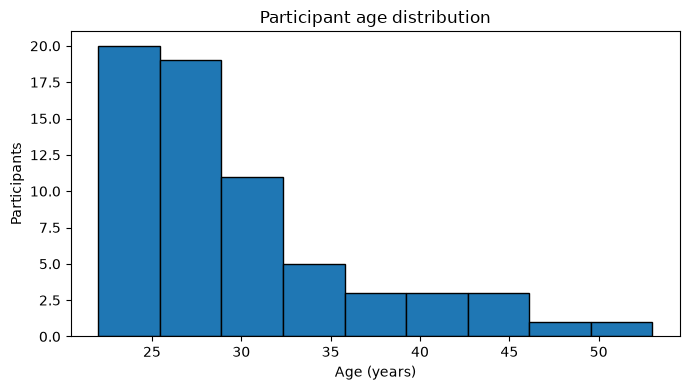

,category,participants
0,Male,39
1,Female,27


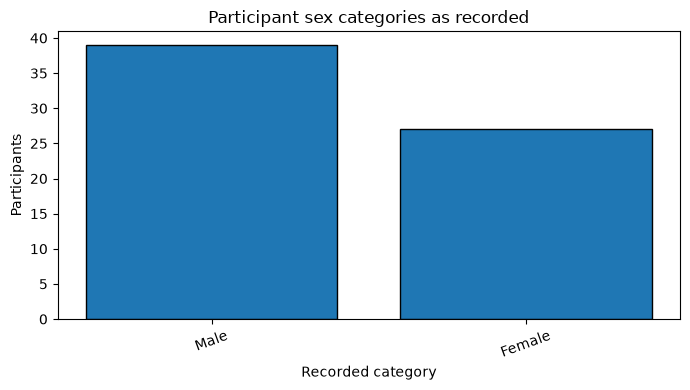

In [5]:
# CELL 5 — demographics overview; do not interpret or use as predictive features here
participants = data.get("participants")
if participants is None:
    print("participants collection not available; skipping demographics plots.")
else:
    display(participants.head())
    age_col = next((c for c in participants.columns if c.lower() == "age"), None)
    sex_col = next((c for c in participants.columns if c.lower() == "sex"), None)

    if age_col:
        age = pd.to_numeric(participants[age_col], errors="coerce").dropna()
        if not age.empty:
            print(age.describe().to_frame("age"))
            plt.figure(figsize=(7, 4))
            plt.hist(age, bins="auto", edgecolor="black")
            plt.title("Participant age distribution")
            plt.xlabel("Age (years)")
            plt.ylabel("Participants")
            plt.tight_layout()
            plt.savefig(FIGURES_DIR / "participant_age_distribution.png", dpi=160, bbox_inches="tight")
            plt.show()
            plt.close()

    if sex_col:
        sex_counts = participants[sex_col].astype("string").fillna("<MISSING>").value_counts()
        display(sex_counts.rename_axis("category").reset_index(name="participants"))
        plt.figure(figsize=(7, 4))
        plt.bar(sex_counts.index.astype(str), sex_counts.values, edgecolor="black")
        plt.title("Participant sex categories as recorded")
        plt.xlabel("Recorded category")
        plt.ylabel("Participants")
        plt.xticks(rotation=20)
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / "participant_sex_categories.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

ECG shape: (132, 15)
ECG columns: ['_id', 'reading_id', 'reading_time', 'wire_id', 'result_classification', 'heart_rate', 'heart_rate_alert', 'firmware_version', 'device_app_version', 'hardware_version', 'username', 'phase', 'waveform_samples', '_waveform_parsed', '_waveform_sample_count']


,_id,reading_id,reading_time,wire_id,result_classification,heart_rate,heart_rate_alert,firmware_version,device_app_version,hardware_version,username,phase,waveform_samples,_waveform_parsed,_waveform_sample_count
0,685a7de0963f0d4b7ea5dd3c,b88b3b90-b60c-11ef-8080-808080808080,10:05:22,0199283d6f42,UNCLASSIFIABLE,46,LOW_HR,20001.210.26,2.16,Charge 6,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,relax,3897 4296 4802 5377 5954 6636 7630 8931 10175 10888 10984 10903 11141 11805 12696 13600 14263 14...,[nan],1
1,685a7e17963f0d4b7ea5dd41,85d45fe0-b60e-11ef-8080-808080808080,10:18:16,0199283d6f42,UNCLASSIFIABLE,46,LOW_HR,20001.210.26,2.16,Charge 6,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,stress,0 353 485 331 10 -316 -599 -886 -1181 -1404 -1496 -1514 -1585 -1793 -2070 -2270 -2372 -2508 -280...,[nan],1
2,685a7e49963f0d4b7ea5dd42,a7992380-4147-11f0-8080-808080808080,15:27:25,817821915242,NSR,78,NONE,20001.210.26,2.16,Charge 6,06c274b06c4badedf4a5710f3af21a338af00c3ac3e6e194be517ee7d28b68c4,relax,-801 -1104 -1342 -1508 -1660 -1888 -2219 -2545 -2757 -2894 -3075 -3343 -3639 -3874 -3995 -4020 -...,[nan],1


Detected columns: {'waveform_samples': 'waveform_samples', 'phase': 'phase', 'participant_id': 'username', 'heart_rate': 'heart_rate'}

Waveform parse diagnostics
Total recordings: 132
Parsed as arrays: 132
Records with at least 2 finite samples: 132
Records not parsed: 0
Records with zero finite samples: 0


,_waveform_sample_count,_waveform_finite_count,_waveform_nonfinite_count,_waveform_min,_waveform_max
count,132.000000,132.000000,132.0,132.000000,132.000000
mean,7499.886364,7499.886364,0.0,-12377.333333,13936.500000
std,1.810266,1.810266,0.0,9909.925860,9034.611578
min,7488.000000,7488.000000,0.0,-32768.000000,2808.000000
25%,7500.000000,7500.000000,0.0,-17586.500000,7277.000000
50%,7500.000000,7500.000000,0.0,-7957.000000,11006.000000
75%,7500.000000,7500.000000,0.0,-4509.750000,18492.250000
max,7501.000000,7501.000000,0.0,-1192.000000,32767.000000


,raw_type,raw_length,raw_preview,parsed_samples,finite_samples
0,str,34792,3897 4296 4802 5377 5954 6636 7630 8931 10175 10888 10984 10903 11141 11805 12696 13600 14263 14...,7500,7500
1,str,34520,0 353 485 331 10 -316 -599 -886 -1181 -1404 -1496 -1514 -1585 -1793 -2070 -2270 -2372 -2508 -280...,7501,7501
2,str,35200,-801 -1104 -1342 -1508 -1660 -1888 -2219 -2545 -2757 -2894 -3075 -3343 -3639 -3874 -3995 -4020 -...,7500,7500
3,str,35128,285 494 656 750 798 837 873 889 869 821 773 746 736 723 694 668 685 769 888 990 1055 1088 1077 9...,7500,7500
4,str,38086,-46 -641 -1021 -1196 -1291 -1390 -1527 -1699 -1877 -2051 -2209 -2314 -2353 -2351 -2327 -2291 -22...,7500,7500


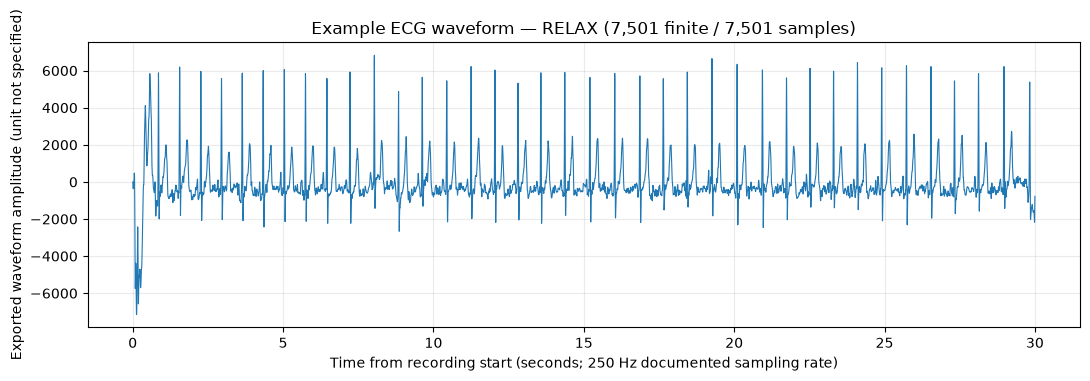

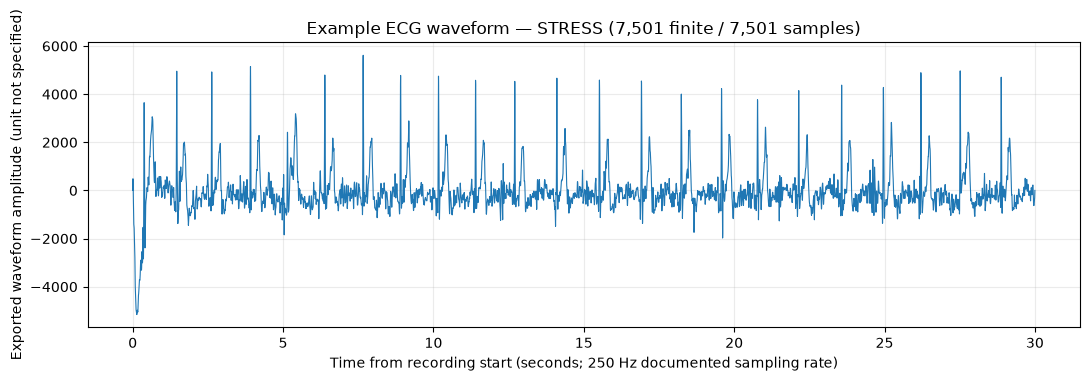


ECG-associated heart-rate records: 132


,count,mean,std,min,25%,50%,75%,max
phase,,,,,,,,
RELAX,66.0,67.833333,10.599831,41.0,61.25,66.5,76.5,94.0
STRESS,66.0,67.424242,10.082827,46.0,60.00,67.0,73.0,93.0


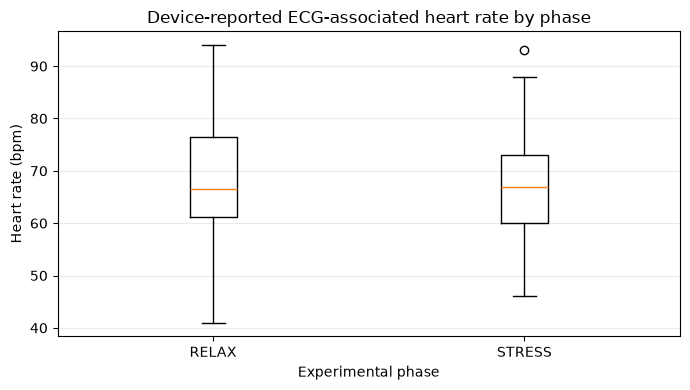

In [16]:
# CELL 6 — inspect ECG metadata and waveform_samples encoding
# ECG sampling rate: 250 Hz (dataset documentation). Amplitude unit is unspecified.

import ast
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ecg = data.get("ecg")


def find_col(df, candidates):
    """Case-insensitive column lookup."""
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None


# Handles JSON/Python list literals and numeric sequences exported with
# comma, semicolon, or whitespace separators. Keeps NaN/Inf for QC; plotting
# below explicitly accounts for non-finite samples.
_NUMBER_PATTERN = re.compile(
    r"[-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?|[-+]?(?:nan|inf(?:inity)?)",
    flags=re.IGNORECASE,
)


def parse_numeric_sequence(value):
    if value is None:
        return None

    if isinstance(value, (list, tuple, np.ndarray)):
        parsed = value
    else:
        try:
            missing = pd.isna(value)
            if isinstance(missing, (bool, np.bool_)) and missing:
                return None
        except (TypeError, ValueError):
            pass

        text = str(value).strip()
        if not text:
            return None

        parsed = None
        for parser in (json.loads, ast.literal_eval):
            try:
                parsed = parser(text)
                break
            except Exception:
                continue

        # Some CSV exports serialize sequences without a JSON/Python list
        # wrapper. Extract numeric tokens rather than assuming commas only.
        if parsed is None:
            tokens = _NUMBER_PATTERN.findall(text)
            if not tokens:
                return None
            try:
                parsed = [float(token) for token in tokens]
            except (ValueError, TypeError):
                return None

    # Accommodate a wrapper object if the export is dictionary-shaped.
    if isinstance(parsed, dict):
        for key in ("waveform_samples", "samples", "values", "data"):
            if key in parsed:
                parsed = parsed[key]
                break

    try:
        arr = np.asarray(parsed, dtype=float).reshape(-1)
        return arr if arr.size else None
    except (ValueError, TypeError, OverflowError):
        return None


if ecg is None or ecg.empty:
    print("ECG collection is missing or empty; no ECG plots can be produced.")
else:
    print("ECG shape:", ecg.shape)
    print("ECG columns:", list(ecg.columns))
    display(ecg.head(3))

    waveform_col = find_col(ecg, ["waveform_samples"])
    phase_col = find_col(ecg, ["phase"])
    user_col = find_col(ecg, ["username", "participant_id", "subject_id"])
    hr_col = find_col(ecg, ["heart_rate"])

    print("Detected columns:", {
        "waveform_samples": waveform_col,
        "phase": phase_col,
        "participant_id": user_col,
        "heart_rate": hr_col,
    })

    if waveform_col is None:
        print("Cannot plot ECG waveform: waveform_samples column was not found.")
        print("Check the schema table and the actual CSV header.")
    else:
        ecg_work = ecg.copy()
        raw_waveforms = ecg_work[waveform_col]
        ecg_work["_waveform_parsed"] = raw_waveforms.map(parse_numeric_sequence)
        ecg_work["_waveform_sample_count"] = ecg_work["_waveform_parsed"].map(
            lambda a: int(a.size) if isinstance(a, np.ndarray) else 0
        )
        ecg_work["_waveform_finite_count"] = ecg_work["_waveform_parsed"].map(
            lambda a: int(np.isfinite(a).sum()) if isinstance(a, np.ndarray) else 0
        )
        ecg_work["_waveform_nonfinite_count"] = (
            ecg_work["_waveform_sample_count"] - ecg_work["_waveform_finite_count"]
        )
        ecg_work["_waveform_min"] = ecg_work["_waveform_parsed"].map(
            lambda a: float(np.nanmin(a)) if isinstance(a, np.ndarray) and np.isfinite(a).any() else np.nan
        )
        ecg_work["_waveform_max"] = ecg_work["_waveform_parsed"].map(
            lambda a: float(np.nanmax(a)) if isinstance(a, np.ndarray) and np.isfinite(a).any() else np.nan
        )

        parsed_records = int(ecg_work["_waveform_parsed"].notna().sum())
        plot_eligible = int((ecg_work["_waveform_finite_count"] >= 2).sum())
        print("\nWaveform parse diagnostics")
        print("Total recordings:", len(ecg_work))
        print("Parsed as arrays:", parsed_records)
        print("Records with at least 2 finite samples:", plot_eligible)
        print("Records not parsed:", int(ecg_work["_waveform_parsed"].isna().sum()))
        print("Records with zero finite samples:", int((ecg_work["_waveform_finite_count"] == 0).sum()))
        display(ecg_work[["_waveform_sample_count", "_waveform_finite_count", "_waveform_nonfinite_count", "_waveform_min", "_waveform_max"]].describe())

        # Show raw representation and parser result for the first records;
        # useful if the exported sequence encoding differs from expectations.
        raw_preview = pd.DataFrame({
            "raw_type": raw_waveforms.map(lambda x: type(x).__name__),
            "raw_length": raw_waveforms.map(lambda x: len(str(x)) if pd.notna(x) else 0),
            "raw_preview": raw_waveforms.map(lambda x: str(x)[:180] if pd.notna(x) else "<missing>"),
            "parsed_samples": ecg_work["_waveform_sample_count"],
            "finite_samples": ecg_work["_waveform_finite_count"],
        })
        display(raw_preview.head(5))

        overview_cols = [c for c in [user_col, phase_col, hr_col] if c is not None]
        overview = ecg_work[overview_cols].copy()
        overview["waveform_sample_count"] = ecg_work["_waveform_sample_count"]
        overview["waveform_finite_count"] = ecg_work["_waveform_finite_count"]
        overview["waveform_min"] = ecg_work["_waveform_min"]
        overview["waveform_max"] = ecg_work["_waveform_max"]
        overview.to_csv(TABLES_DIR / "ecg_recording_overview.csv", index=False)

        if phase_col is None:
            print("Cannot split ECG plots by phase: phase column was not found.")
        else:
            phase_values = ecg_work[phase_col].astype("string").str.strip().str.upper()
            for phase_name in ("RELAX", "STRESS"):
                mask = (phase_values == phase_name) & (ecg_work["_waveform_finite_count"] >= 2)
                candidates = ecg_work.loc[mask].copy()
                if candidates.empty:
                    print(f"No plottable ECG waveform for {phase_name}. Check raw_preview and waveform diagnostics above.")
                    continue

                # Do not blindly plot the first parsed record: select the record
                # with the largest number of finite samples to avoid choosing
                # an empty/all-NaN waveform when a usable recording follows.
                row_idx = candidates["_waveform_finite_count"].idxmax()
                row = candidates.loc[row_idx]
                signal = row["_waveform_parsed"]
                sample_positions = np.arange(signal.size)
                time_seconds = sample_positions / 250.0
                signal_for_plot = np.where(np.isfinite(signal), signal, np.nan)

                plt.figure(figsize=(11, 3.8))
                plt.plot(time_seconds, signal_for_plot, linewidth=0.8)
                plt.title(
                    f"Example ECG waveform — {phase_name} "
                    f"({int(np.isfinite(signal).sum()):,} finite / {signal.size:,} samples)"
                )
                plt.xlabel("Time from recording start (seconds; 250 Hz documented sampling rate)")
                plt.ylabel("Exported waveform amplitude (unit not specified)")
                plt.grid(True, alpha=0.25)
                plt.tight_layout()
                plt.savefig(FIGURES_DIR / f"ecg_example_{phase_name.lower()}.png", dpi=160, bbox_inches="tight")
                plt.show()
                plt.close()

    # ECG-associated heart-rate summary is independent of waveform parsing.
    if phase_col is not None and hr_col is not None:
        hr = pd.to_numeric(ecg[hr_col], errors="coerce")
        phase = ecg[phase_col].astype("string").str.strip().str.upper()
        hr_temp = pd.DataFrame({"phase": phase, "heart_rate_bpm": hr}).dropna()
        hr_temp = hr_temp[np.isfinite(hr_temp["heart_rate_bpm"])]

        print("\nECG-associated heart-rate records:", len(hr_temp))
        if not hr_temp.empty:
            display(hr_temp.groupby("phase")["heart_rate_bpm"].describe())
            phases = [p for p in ("RELAX", "STRESS") if (hr_temp["phase"] == p).any()]
            values = [hr_temp.loc[hr_temp["phase"] == p, "heart_rate_bpm"].to_numpy() for p in phases]
            if values:
                plt.figure(figsize=(7, 4))
                plt.boxplot(values, tick_labels=phases)
                plt.title("Device-reported ECG-associated heart rate by phase")
                plt.xlabel("Experimental phase")
                plt.ylabel("Heart rate (bpm)")
                plt.grid(axis="y", alpha=0.25)
                plt.tight_layout()
                plt.savefig(FIGURES_DIR / "ecg_heart_rate_by_phase.png", dpi=160, bbox_inches="tight")
                plt.show()
                plt.close()
        else:
            print("No finite numeric heart-rate values available for the HR boxplot.")
    else:
        print("ECG heart-rate-by-phase plot skipped: phase or heart_rate column missing.")


,username,phase,time_sec,valid_data,activation,scl_avg
0,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,relax,0,False,0.0,43.17
1,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,relax,0,False,0.0,43.23
2,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,relax,5,True,0.0,43.32
3,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,relax,5,True,1.0,43.46
4,6683f97240e6fd3620594043bee323169ed91d789c7e996e78dd3b461e90c1c4,relax,5,True,0.0,43.63


valid_data value counts:


,valid_data,rows
0,True,19708
1,False,386


Rows marked valid: 19708
Rows marked invalid: 386


,username,phase,rows
0,02b865b4b8a0f6319640b266de23bd0cfdffc345e75ec64c5772ca659541e3f7,relax,163
1,036e6da345803c97c92d64a489ecdfefd93adb7cd9474322e3fdc455164372da,relax,163
2,036e6da345803c97c92d64a489ecdfefd93adb7cd9474322e3fdc455164372da,stress,163
3,06c274b06c4badedf4a5710f3af21a338af00c3ac3e6e194be517ee7d28b68c4,relax,163
4,06c274b06c4badedf4a5710f3af21a338af00c3ac3e6e194be517ee7d28b68c4,stress,162
5,09223ce6fe3b28d121bf18df0e4e8f09622209678abf7b706bc780646dbf2d53,relax,160
6,09223ce6fe3b28d121bf18df0e4e8f09622209678abf7b706bc780646dbf2d53,stress,162
7,0e1d276d538d521abc42245a3920f6282c3279e0337caf7d3435fa0c424db705,relax,158
8,0e1d276d538d521abc42245a3920f6282c3279e0337caf7d3435fa0c424db705,stress,163
9,0f53170a435a716c32ea8392d549ba057b4e29c50bb12f01eb9f99f643134f7c,relax,158


Original time_sec distribution and duplicate timestamp count:


,time_sec
count,20094.000000
mean,49.516522
std,336.829681
min,-3494.000000
25%,40.000000
50%,81.000000
75%,121.000000
max,163.000000


Rows with repeated time_sec values (within the full table): 20094
SCL summary among rows marked valid (or all rows if no valid_data field):


,scl_avg_uS
count,19708.000000
mean,38.455935
std,8.768025
min,2.290000
25%,32.750000
50%,39.850000
75%,44.530000
max,56.460000


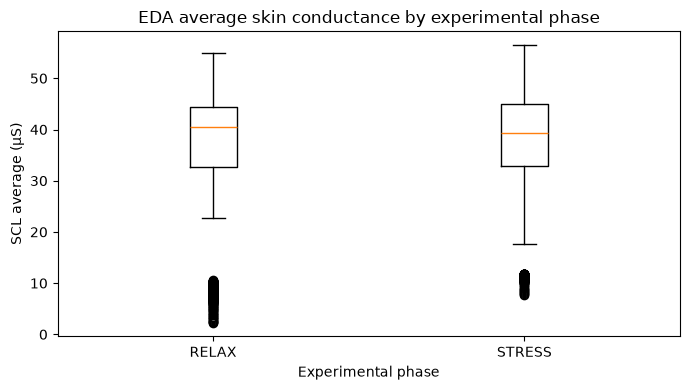

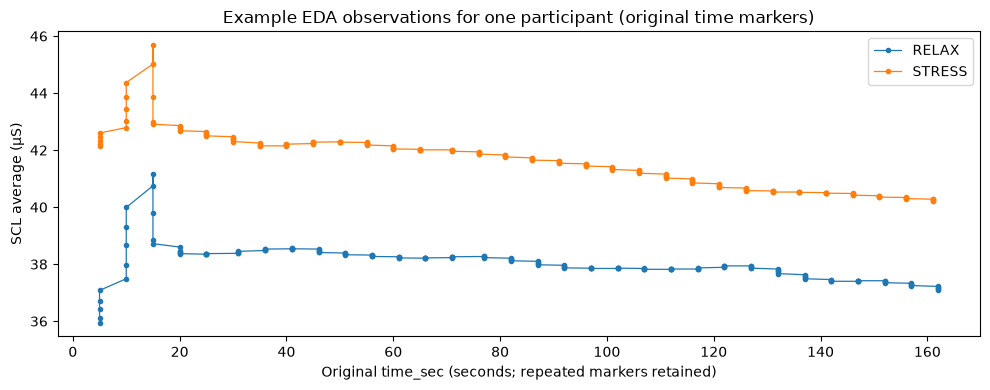

In [9]:
# CELL 7 — EDA summaries and plots
eda = data.get("eda")
if eda is None:
    print("EDA collection unavailable; skipping.")
else:
    display(eda.head())
    eda_user = find_col(eda, ["username", "participant_id", "subject_id"])
    eda_phase = find_col(eda, ["phase"])
    time_col = find_col(eda, ["time_sec"])
    scl_col = find_col(eda, ["scl_avg"])
    valid_col = find_col(eda, ["valid_data"])

    eda_work = eda.copy()
    if valid_col:
        valid_text = eda_work[valid_col].astype("string").str.strip().str.lower()
        eda_work["_valid_bool"] = valid_text.map({"true": True, "false": False, "1": True, "0": False, "yes": True, "no": False})
        print("valid_data value counts:")
        display(eda_work[valid_col].astype("string").value_counts(dropna=False).rename_axis("valid_data").reset_index(name="rows"))
        print("Rows marked valid:", int((eda_work["_valid_bool"] == True).sum()))
        print("Rows marked invalid:", int((eda_work["_valid_bool"] == False).sum()))

    if eda_user and eda_phase:
        recording_coverage = (
            eda_work.groupby([eda_user, eda_phase], dropna=False)
            .size().rename("rows").reset_index()
        )
        display(recording_coverage.head(20))
        recording_coverage.to_csv(TABLES_DIR / "eda_participant_phase_row_counts.csv", index=False)

    if time_col:
        eda_work["_time_sec_numeric"] = pd.to_numeric(eda_work[time_col], errors="coerce")
        print("Original time_sec distribution and duplicate timestamp count:")
        display(eda_work["_time_sec_numeric"].describe().to_frame("time_sec"))
        print("Rows with repeated time_sec values (within the full table):", int(eda_work["_time_sec_numeric"].duplicated(keep=False).sum()))
        # Do not drop or collapse repeated time markers.

    if scl_col:
        eda_work["_scl_numeric"] = pd.to_numeric(eda_work[scl_col], errors="coerce")
        plot_data = eda_work.copy()
        if "_valid_bool" in plot_data:
            plot_data = plot_data.loc[plot_data["_valid_bool"] == True]
        print("SCL summary among rows marked valid (or all rows if no valid_data field):")
        display(plot_data["_scl_numeric"].describe().to_frame("scl_avg_uS"))
        if eda_phase:
            phases = [p for p in ["RELAX", "STRESS"] if (plot_data[eda_phase].astype("string").str.upper() == p).any()]
            phase_series = plot_data[eda_phase].astype("string").str.strip().str.upper()
            values = [plot_data.loc[phase_series == p, "_scl_numeric"].dropna().values for p in phases]
            values = [v for v in values if len(v)]
            labels = [p for p in phases if len(plot_data.loc[phase_series == p, "_scl_numeric"].dropna())]
            if values:
                plt.figure(figsize=(7, 4))
                plt.boxplot(values, tick_labels=labels)
                plt.title("EDA average skin conductance by experimental phase")
                plt.xlabel("Experimental phase")
                plt.ylabel("SCL average (µS)")
                plt.tight_layout()
                plt.savefig(FIGURES_DIR / "eda_scl_by_phase_valid_rows.png", dpi=160, bbox_inches="tight")
                plt.show()
                plt.close()

        # Example traces: select participant with most EDA rows, and preserve original time_sec values.
        if eda_user and eda_phase and time_col:
            counts = eda_work.groupby(eda_user).size().sort_values(ascending=False)
            if not counts.empty:
                selected_id = counts.index[0]
                example = eda_work.loc[eda_work[eda_user] == selected_id].copy()
                example["_phase_upper"] = example[eda_phase].astype("string").str.strip().str.upper()
                if "_time_sec_numeric" in example and "_scl_numeric" in example:
                    plt.figure(figsize=(10, 4))
                    plotted = False
                    for phase_name in ["RELAX", "STRESS"]:
                        subset = example.loc[example["_phase_upper"] == phase_name].sort_values("_time_sec_numeric")
                        if len(subset):
                            if "_valid_bool" in subset:
                                subset = subset.loc[subset["_valid_bool"] == True]
                            plt.plot(subset["_time_sec_numeric"], subset["_scl_numeric"], marker=".", linewidth=0.9, label=phase_name)
                            plotted = True
                    if plotted:
                        plt.title("Example EDA observations for one participant (original time markers)")
                        plt.xlabel("Original time_sec (seconds; repeated markers retained)")
                        plt.ylabel("SCL average (µS)")
                        plt.legend()
                        plt.tight_layout()
                        plt.savefig(FIGURES_DIR / "eda_example_original_time_markers.png", dpi=160, bbox_inches="tight")
                        plt.show()
                    plt.close()



fitbit_heart_rate_per_second — first rows


,username,time,value
0,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:11:50,90
1,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:11:52,84
2,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:11:54,77
3,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:11:56,75
4,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:11:58,73


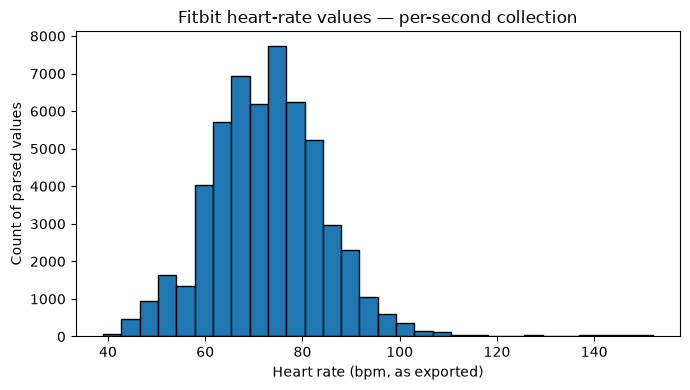


fitbit_heart_rate_per_minute — first rows


,username,time,value
0,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:12:00,63
1,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:13:00,60
2,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:14:00,59
3,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:15:00,61
4,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:16:00,61


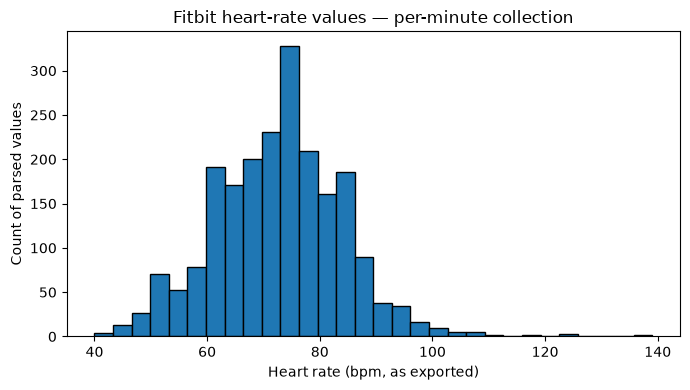

,collection,rows,value_field,time_field,participant_count,numeric_value_count_after_parsing,rows_with_sequence_values,median_sequence_length,value_min,value_median,value_max
0,fitbit_heart_rate_per_second,54462,value,time,66,54462,0,NaN,39.0,72.0,152.0
1,fitbit_heart_rate_per_minute,2131,value,time,66,2131,0,NaN,40.0,73.0,139.0


In [12]:
# CELL 8 — inspect HR field shape and numeric value distributions
# The released HR collections may store time/value information at row or sequence level.
# This section reports what is actually present and does not infer phase boundaries.


def numeric_values_from_series(series: pd.Series) -> np.ndarray:
    collected = []
    for value in series.dropna():
        seq = parse_numeric_sequence(value)
        if seq is not None:
            collected.extend(seq[np.isfinite(seq)].tolist())
            continue
        try:
            number = float(value)
            if np.isfinite(number):
                collected.append(number)
        except Exception:
            pass
    return np.asarray(collected, dtype=float)


hr_collection_summaries = []
for name in ["fitbit_heart_rate_per_second", "fitbit_heart_rate_per_minute"]:
    df = data.get(name)
    if df is None:
        continue
    print(f"\n{name} — first rows")
    display(df.head())
    value_col = find_col(df, ["value", "heart_rate", "bpm"])
    time_col = find_col(df, ["time", "timestamp", "datetime"])
    user_col = find_col(df, ["username", "participant_id", "subject_id"])
    if value_col is None:
        print("No recognised numeric value column; no HR value plot generated.")
        continue
    numeric_values = numeric_values_from_series(df[value_col])
    seq_lens = []
    for raw in df[value_col].dropna():
        seq = parse_numeric_sequence(raw)
        if seq is not None and seq.size > 1:
            seq_lens.append(int(seq.size))
    hr_collection_summaries.append({
        "collection": name,
        "rows": len(df),
        "value_field": value_col,
        "time_field": time_col or "not found",
        "participant_count": int(df[user_col].nunique(dropna=True)) if user_col else np.nan,
        "numeric_value_count_after_parsing": int(numeric_values.size),
        "rows_with_sequence_values": len(seq_lens),
        "median_sequence_length": float(np.median(seq_lens)) if seq_lens else np.nan,
        "value_min": float(np.min(numeric_values)) if numeric_values.size else np.nan,
        "value_median": float(np.median(numeric_values)) if numeric_values.size else np.nan,
        "value_max": float(np.max(numeric_values)) if numeric_values.size else np.nan,
    })
    if numeric_values.size:
        plt.figure(figsize=(7, 4))
        plt.hist(numeric_values, bins=30, edgecolor="black")
        resolution = "per-second" if "second" in name else "per-minute"
        plt.title(f"Fitbit heart-rate values — {resolution} collection")
        plt.xlabel("Heart rate (bpm, as exported)")
        plt.ylabel("Count of parsed values")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"{name}_value_distribution.png", dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

hr_collection_summary = pd.DataFrame(hr_collection_summaries)
display(hr_collection_summary)
hr_collection_summary.to_csv(TABLES_DIR / "fitbit_hr_representation_summary.csv", index=False)

# The per-minute/per-second exports do not necessarily include phase labels.
# No RELAX/STRESS assignment is made here based only on time-of-day or row order.


pss_14 — preview


,username,time,score,"In the last month, how often have you felt everything was under control?","In the last month, how often have you felt unable to control important things in your life?","In the last month, how often have you been upset by something that happened unexpectedly?","In the last month, how often have you been angry because things that happened were outside your control?","In the last month, how often have you felt confident in your ability to handle personal problems?","In the last month, how often have you successfully handled small irritations of life?","In the last month, how often have you thought about the things you still have to do?","In the last month, how often have you been able to control how you spend your time?","En el último mes, ¿con qué frecuencia ha podido controlar las dificultades de su vida?","In the last month, how often have you felt you effectively managed important changes in your life?","In the last month, how often have things gone well for you?","In the last month, how often have you felt that difficulties pile up so much that you cannot overcome them?","In the last month, how often have you felt unable to cope with all the things you had to do?","In the last month, how often have you felt nervous or stressed?"
0,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:07:52,15,3. Often,0. Nunca,1. Almost never,1. Almost never,4. Very often,4. Very often,3. Often,3. Often,4. Very often,2. Sometimes,4. Very often,0. Nunca,4. Very often,2. Sometimes
1,c5aafe0dcea9f474d9284c2c0824251b18e2fce7cc072b62d49cd6b0ba61ffdc,13:00:30,34,2. Sometimes,1. Almost never,1. Almost never,3. Often,2. Sometimes,0. Nunca,4. Very often,3. Often,1. Almost never,0. Nunca,2. Sometimes,3. Often,2. Sometimes,2. Sometimes
2,17fc54dbc1172a9c00cc8a931412bc0b65dc3b51507cbbf5c87db086c8f925c3,15:13:05,27,1. Almost never,2. Sometimes,2. Sometimes,2. Sometimes,3. Often,3. Often,3. Often,2. Sometimes,2. Sometimes,2. Sometimes,3. Often,1. Almost never,2. Sometimes,3. Often
3,681d14e7c42936e4697b208db3a796a722d6c6b3a5cdc9395fff02719acddf1e,16:00:23,23,2. Sometimes,1. Almost never,2. Sometimes,0. Nunca,3. Often,4. Very often,3. Often,2. Sometimes,3. Often,3. Often,3. Often,4. Very often,2. Sometimes,3. Often
4,5ec31ef967e738a8340a03792c4e2fea2f2435c800ac55f2e84fc703d69158d7,12:10:27,11,3. Often,1. Almost never,1. Almost never,1. Almost never,4. Very often,4. Very often,3. Often,4. Very often,3. Often,4. Very often,4. Very often,0. Nunca,1. Almost never,2. Sometimes


pss_14 score summary:


,score
count,66.000000
mean,24.030303
std,8.595114
min,4.000000
25%,19.000000
50%,24.000000
75%,29.750000
max,45.000000


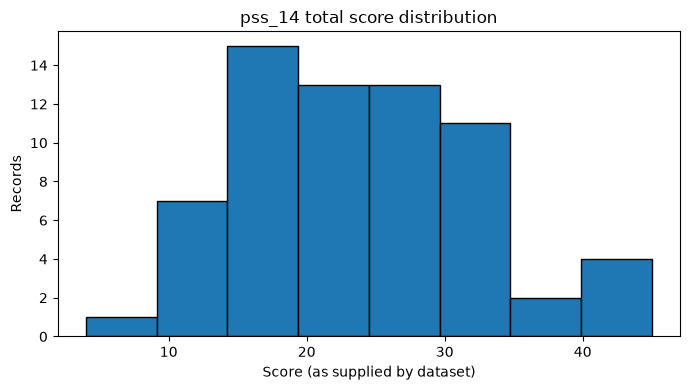


stai — preview


,username,time,phase,score,At this moment I feel good,I feel upset,I feel jittery,I feel worried,I am presently worrying about possible future misfortunes,I am relaxed,I am tense,I feel happy,I feel agitated,I feel distressed,I feel confused and over-excited,I feel calm,I feel at ease,I feel comfortable,I feel rested,"""I feel strained""",I feel nervous,I feel satisfied,I feel secure,I have self-confidence
0,de5e2d680abaf4b3b55e2e7323836eb55e08829ab4f8081f08df716fd7b92ff2,12:24:40,relax,25,3. Very much,0. Not at all,0. Not at all,0. Not at all,0. Not at all,2. Quite a bit,0. Not at all,2. Quite a bit,0. Not at all,0. Not at all,0. Not at all,3. Very much,3. Very much,3. Very much,1. A little,0. Not at all,0. Not at all,3. Very much,3. Very much,2. Quite a bit
1,c5aafe0dcea9f474d9284c2c0824251b18e2fce7cc072b62d49cd6b0ba61ffdc,13:15:24,relax,30,3. Very much,0. Not at all,1. A little,0. Not at all,0. Not at all,2. Quite a bit,0. Not at all,2. Quite a bit,0. Not at all,0. Not at all,0. Not at all,2. Quite a bit,3. Very much,3. Very much,2. Quite a bit,2. Quite a bit,0. Not at all,2. Quite a bit,2. Quite a bit,2. Quite a bit
2,17fc54dbc1172a9c00cc8a931412bc0b65dc3b51507cbbf5c87db086c8f925c3,15:26:12,relax,34,2. Quite a bit,0. Not at all,0. Not at all,1. A little,1. A little,2. Quite a bit,0. Not at all,1. A little,0. Not at all,0. Not at all,0. Not at all,2. Quite a bit,2. Quite a bit,2. Quite a bit,2. Quite a bit,0. Not at all,0. Not at all,1. A little,2. Quite a bit,2. Quite a bit
3,681d14e7c42936e4697b208db3a796a722d6c6b3a5cdc9395fff02719acddf1e,16:17:25,relax,32,2. Quite a bit,0. Not at all,0. Not at all,1. A little,0. Not at all,1. A little,0. Not at all,2. Quite a bit,0. Not at all,0. Not at all,1. A little,2. Quite a bit,2. Quite a bit,3. Very much,2. Quite a bit,2. Quite a bit,0. Not at all,3. Very much,3. Very much,2. Quite a bit
4,5ec31ef967e738a8340a03792c4e2fea2f2435c800ac55f2e84fc703d69158d7,12:22:23,relax,26,3. Very much,0. Not at all,0. Not at all,1. A little,1. A little,2. Quite a bit,0. Not at all,2. Quite a bit,0. Not at all,0. Not at all,0. Not at all,3. Very much,3. Very much,3. Very much,2. Quite a bit,0. Not at all,0. Not at all,2. Quite a bit,3. Very much,3. Very much


stai score summary:


,score
count,132.000000
mean,35.128788
std,8.122540
min,23.000000
25%,28.000000
50%,34.000000
75%,40.000000
max,58.000000


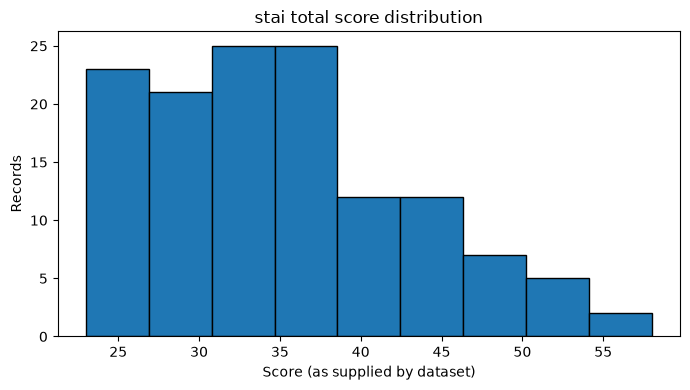

,count,mean,std,min,25%,50%,75%,max
_phase_upper,,,,,,,,
RELAX,66.0,33.515152,7.342694,23.0,27.0,33.0,37.75,56.0
STRESS,66.0,36.742424,8.588562,24.0,30.0,36.5,43.00,58.0


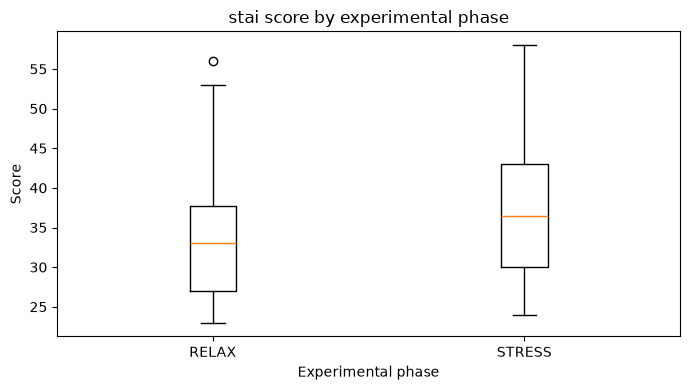

In [14]:
# CELL 9 — questionnaire distributions
# PSS-14 refers to perceived stress over the past month; it is not a phase-specific label.
# STAI-S is state anxiety and may be recorded for both experimental phases.

for name in ["pss_14", "stai"]:
    df = data.get(name)
    if df is None:
        print(f"{name} collection unavailable; skipping.")
        continue
    print(f"\n{name} — preview")
    display(df.head())
    score_col = find_col(df, ["score", "total_score", "pss_score", "stai_score"])
    phase_col = find_col(df, ["phase"])
    if score_col is None:
        print("No recognised total score column; inspect the schema table for the correct field name.")
        continue
    df_score = df.copy()
    df_score["_score_numeric"] = pd.to_numeric(df_score[score_col], errors="coerce")
    print(f"{name} score summary:")
    display(df_score["_score_numeric"].describe().to_frame("score"))
    plt.figure(figsize=(7, 4))
    plt.hist(df_score["_score_numeric"].dropna(), bins="auto", edgecolor="black")
    plt.title(f"{name} total score distribution")
    plt.xlabel("Score (as supplied by dataset)")
    plt.ylabel("Records")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}_score_distribution.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    if phase_col:
        df_score["_phase_upper"] = df_score[phase_col].astype("string").str.strip().str.upper()
        display(df_score.groupby("_phase_upper")["_score_numeric"].describe())
        phases = [p for p in ["RELAX", "STRESS"] if (df_score["_phase_upper"] == p).any()]
        values = [df_score.loc[df_score["_phase_upper"] == p, "_score_numeric"].dropna().values for p in phases]
        keep = [(p, v) for p, v in zip(phases, values) if len(v)]
        if keep:
            plt.figure(figsize=(7, 4))
            plt.boxplot([v for _, v in keep], tick_labels=[p for p, _ in keep])
            plt.title(f"{name} score by experimental phase")
            plt.xlabel("Experimental phase")
            plt.ylabel("Score")
            plt.tight_layout()
            plt.savefig(FIGURES_DIR / f"{name}_score_by_phase.png", dpi=160, bbox_inches="tight")
            plt.show()
            plt.close()

In [15]:
# CELL 10 — check whether participant IDs and phase labels are present across collections
# This is only a linkage inventory. It does not merge sensor measurements.
linkage_rows = []
for name, df in data.items():
    user_col = find_col(df, ["username", "participant_id", "subject_id"])
    phase_col = find_col(df, ["phase"])
    ids = set(df[user_col].dropna().astype(str)) if user_col else set()
    phases = set(df[phase_col].dropna().astype(str).str.strip().str.upper()) if phase_col else set()
    linkage_rows.append({
        "collection": name,
        "has_participant_id": user_col is not None,
        "participant_id_field": user_col or "not found",
        "unique_participant_ids": len(ids) if user_col else np.nan,
        "has_phase_field": phase_col is not None,
        "phase_values_observed": ", ".join(sorted(phases)) if phases else "not available",
    })
linkage_inventory = pd.DataFrame(linkage_rows)
display(linkage_inventory)
linkage_inventory.to_csv(TABLES_DIR / "cross_collection_linkage_inventory.csv", index=False)

# Pairwise participant ID overlap is useful for planning, but does not prove time alignment.
collection_ids = {}
for name, df in data.items():
    user_col = find_col(df, ["username", "participant_id", "subject_id"])
    if user_col:
        collection_ids[name] = set(df[user_col].dropna().astype(str))
overlap_rows = []
names = list(collection_ids)
for i, left in enumerate(names):
    for right in names[i + 1:]:
        overlap_rows.append({
            "collection_a": left,
            "collection_b": right,
            "shared_participant_ids": len(collection_ids[left] & collection_ids[right]),
            "participants_only_in_a": len(collection_ids[left] - collection_ids[right]),
            "participants_only_in_b": len(collection_ids[right] - collection_ids[left]),
        })
participant_overlap = pd.DataFrame(overlap_rows)
display(participant_overlap)
participant_overlap.to_csv(TABLES_DIR / "participant_id_overlap.csv", index=False)

,collection,has_participant_id,participant_id_field,unique_participant_ids,has_phase_field,phase_values_observed
0,ecg,True,username,66,True,"RELAX, STRESS"
1,eda,True,username,64,True,"RELAX, STRESS"
2,fitbit_heart_rate_per_minute,True,username,66,False,not available
3,fitbit_heart_rate_per_second,True,username,66,False,not available
4,fitbit_heart_rate_summary,True,username,66,False,not available
5,participants,True,username,66,False,not available
6,pss_14,True,username,66,False,not available
7,stai,True,username,66,True,"RELAX, STRESS"


,collection_a,collection_b,shared_participant_ids,participants_only_in_a,participants_only_in_b
0,ecg,eda,64,2,0
1,ecg,fitbit_heart_rate_per_minute,66,0,0
2,ecg,fitbit_heart_rate_per_second,66,0,0
3,ecg,fitbit_heart_rate_summary,66,0,0
4,ecg,participants,66,0,0
5,ecg,pss_14,66,0,0
6,ecg,stai,66,0,0
7,eda,fitbit_heart_rate_per_minute,64,0,2
8,eda,fitbit_heart_rate_per_second,64,0,2
9,eda,fitbit_heart_rate_summary,64,0,2


In [17]:
# CELL 11 — write a concise EDA report at project root
report = [
    "# QoL_Stress exploratory data analysis",
    "",
    f"- Project root: `{PROJECT_ROOT}`",
    f"- Dataset root: `{DATASET_ROOT}`",
    f"- Collections loaded: {len(data)}",
    f"- Collections missing: {', '.join(missing_collections) if missing_collections else 'None'}",
    "",
    "## Collection inventory",
    "",
    "| Collection | Rows | Columns | Participants | Duplicate rows |",
    "|---|---:|---:|---:|---:|",
]
for row in load_summary.to_dict(orient="records"):
    pcount = "n/a" if pd.isna(row["participant_count"]) else int(row["participant_count"])
    report.append(f"| {row['collection']} | {row['rows']} | {row['columns']} | {pcount} | {row['duplicate_rows']} |")

report += [
    "",
    "## Outputs",
    "",
    "- `reports/tables/eda_collection_load_summary.csv`",
    "- `reports/tables/eda_schema_missingness.csv`",
    "- `reports/tables/eda_participant_coverage.csv`",
    "- `reports/tables/eda_phase_distribution.csv`",
    "- `reports/tables/eda_phase_participant_coverage.csv`",
    "- `reports/tables/eda_participant_phase_row_counts.csv` (when EDA participant/phase fields exist)",
    "- `reports/tables/ecg_recording_overview.csv` (when ECG waveform field exists)",
    "- `reports/tables/fitbit_hr_representation_summary.csv`",
    "- `reports/tables/cross_collection_linkage_inventory.csv`",
    "- `reports/tables/participant_id_overlap.csv`",
    "- Figures: `reports/figures/`",
    "",
    "## Interpretation restrictions",
    "",
    "1. `RELAX` and `STRESS` are experimental protocol phases, not clinical diagnoses.",
    "2. EDA `time_sec` values and repeated timestamps are retained as exported; no interpolation or resampling was performed.",
    "3. ECG waveform amplitude units are not assumed. The example plot is an unfiltered exported waveform.",
    "4. Fitbit heart-rate data are not assigned phase labels based on guessed clock-time boundaries.",
    "5. Participant ID overlap does not establish temporal synchronisation between modalities.",
    "6. Descriptive distributions are not clinical reference ranges or validated decision thresholds.",
    "",
    "## Before preprocessing / feature extraction",
    "",
    "- Confirm each collection's row semantics against the official PhysioNet data description.",
    "- Confirm the ECG waveform parser successfully decoded all or nearly all recordings; investigate any failures.",
    "- Decide whether the first model should use ECG recording-level features, EDA recording-level features, or another clearly defined single modality.",
    "- Preserve participant grouping for all validation. Do not randomly split rows or windows across participants.",
    "- Keep all scaling, imputation, feature selection, and tuning inside each training fold.",
    "- Do not fuse modalities until their participant, phase, and time alignment is demonstrated.",
    "",
    "## Scientific scope",
    "",
    "This dataset supports an exploratory study of physiological responses under a controlled experimental stress protocol in healthy adults. It does not by itself validate astronaut stress monitoring, chronic stress diagnosis, or clinical use.",
]
report_path = REPORTS_DIR / "eda_summary.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print("EDA report saved:", report_path)
print("Tables saved in:", TABLES_DIR)
print("Figures saved in:", FIGURES_DIR)

EDA report saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\eda_summary.md
Tables saved in: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\tables
Figures saved in: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\figures
